Name : Bhalchim Roshani Ramchandra  
Roll No. : 08  
Title : Data Aggregation  
Problem Statement: Analyzing Sales Performance by Region in a Retail Company  
Dataset: "Retail_Sales_Data.csv"  
Description: The dataset contains information about sales transactions in a retail company. It
includes attributes such as transaction date, product category, quantity sold, and sales
amount. The goal is to perform data aggregation to analyze the sales performance by region
and identify the top-performing regions.
Tasks to Perform:
1. Import the "Retail_Sales_Data.csv" dataset.
2. Explore the dataset to understand its structure and content.
3. Identify the relevant variables for aggregating sales data, such as region, sales
amount, and product category.
4. Group the sales data by region and calculate the total sales amount for each region.
5. Create bar plots or pie charts to visualize the sales distribution by region.
6. Identify the top-performing regions based on the highest sales amount.
7. Group the sales data by region and product category to calculate the total sales
amount for each combination.
8. Create stacked bar plots or grouped bar plots to compare the sales amounts across
different regions and product categories.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("retail_sales_dataset.csv")
print(df.head())
print("Shape:", df.shape)
print(df.columns)
print(df.isnull().sum())

   Transaction ID        Date Customer ID  Gender  Age Product Category  \
0               1  2023-11-24     CUST001    Male   34           Beauty   
1               2  2023-02-27     CUST002  Female   26         Clothing   
2               3  2023-01-13     CUST003    Male   50      Electronics   
3               4  2023-05-21     CUST004    Male   37         Clothing   
4               5  2023-05-06     CUST005    Male   30           Beauty   

   Quantity  Price per Unit  Total Amount  
0         3              50           150  
1         2             500          1000  
2         1              30            30  
3         1             500           500  
4         2              50           100  
Shape: (1000, 9)
Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='str')
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0


In [5]:
df = df.drop_duplicates()
df = df.dropna(subset=["Product Category", "Total Amount"])

print(df.describe())

       Transaction ID         Age     Quantity  Price per Unit  Total Amount
count     1000.000000  1000.00000  1000.000000     1000.000000   1000.000000
mean       500.500000    41.39200     2.514000      179.890000    456.000000
std        288.819436    13.68143     1.132734      189.681356    559.997632
min          1.000000    18.00000     1.000000       25.000000     25.000000
25%        250.750000    29.00000     1.000000       30.000000     60.000000
50%        500.500000    42.00000     3.000000       50.000000    135.000000
75%        750.250000    53.00000     4.000000      300.000000    900.000000
max       1000.000000    64.00000     4.000000      500.000000   2000.000000


In [6]:
sales = df.groupby("Product Category")["Total Amount"].sum()
print(sales)

Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64


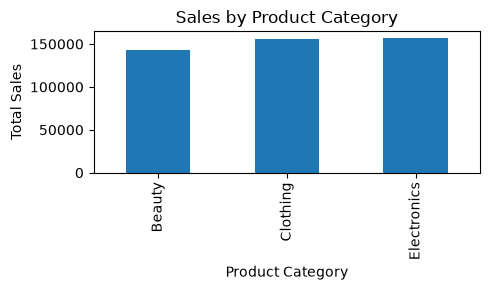

In [7]:
sales.plot(kind="bar", figsize=(5, 3))
plt.title("Sales by Product Category")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

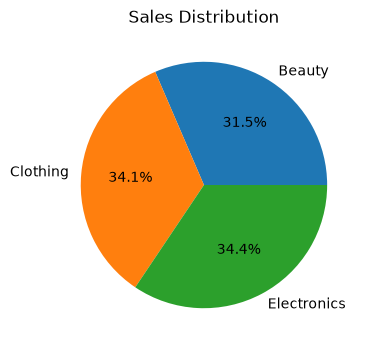

In [8]:
sales.plot(kind="pie", autopct="%1.1f%%", figsize=(4, 4))
plt.title("Sales Distribution")
plt.ylabel("")
plt.show()

In [9]:
print(sales.sort_values(ascending=False))
print("\nTop Category:", sales.idxmax())

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

Top Category: Electronics


In [10]:
table = df.pivot_table(
    index="Gender",
    columns="Product Category",
    values="Total Amount",
    aggfunc="sum",
    fill_value=0
)

print(table)

Product Category  Beauty  Clothing  Electronics
Gender                                         
Female             74830     81275        76735
Male               68685     74305        80170


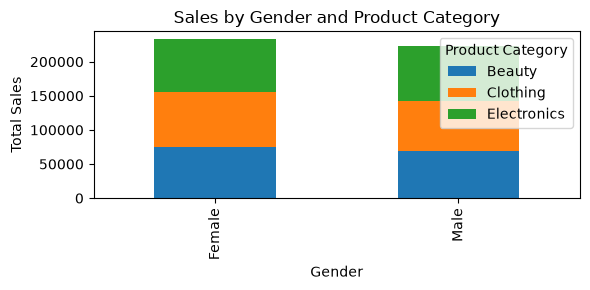

In [11]:
table.plot(kind="bar", stacked=True, figsize=(6, 3))
plt.title("Sales by Gender and Product Category")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()